# Rice Variety Classification with Convolutional Neural Networks

## Introduction

Rice is one of the most widely produced grains in the world and is grown in many genetic varieties. These varieties differ in grain shape, size, texture and colour, and telling them apart matters for seed quality control, pricing and food labelling. Doing this by eye is slow and inconsistent, which makes it a natural task for computer vision.

This project trains convolutional neural networks (CNNs) to classify single rice grains from images into five varieties: **Arborio, Basmati, Ipsala, Jasmine and Karacadag**.

### Dataset

The [Rice Image Dataset](https://www.muratkoklu.com/datasets/) (Koklu, Cinar & Taspinar, 2021) contains **75,000 RGB images** of single rice grains on a black background, **15,000 per variety**, at 250 × 250 pixels. Because every class has the same number of images, accuracy is a meaningful metric without reweighting.

### Objectives

1. Build a data pipeline that loads the images and splits them into training and validation sets.
2. Explore the dataset: class distribution and example images.
3. Train and compare three compact CNN architectures.
4. Study how network depth, the declared input shape and early stopping affect performance.

### Notebook outline

| Section | Content |
|---|---|
| 1. Setup | Imports and hyperparameters |
| 2. Data | Loading, train/validation split, class distribution, sample images |
| 3. Model 1 | One convolutional block |
| 4. Model 2 | Two convolutional blocks with early stopping |
| 5. Model 3 | Model 2 with the input shape matched to the data |
| 6. Conclusion | Results and analysis |

**Reference:** Koklu, M., Cinar, I., & Taspinar, Y. S. (2021). Classification of rice varieties with deep learning methods. *Computers and Electronics in Agriculture*, 187, 106285. https://doi.org/10.1016/j.compag.2021.106285

---

## 1. Setup

Import Keras, the layers used to build the models, and pandas for tabular summaries.

In [1]:
import keras #point : you soulud import tensorflow first!
from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation, Conv2D, MaxPooling2D, GlobalMaxPooling2D, BatchNormalization, Input, Rescaling
import pandas as pd

/Users/mohammadaminsaeini/Desktop/ML/Homework/cnn_rice/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


### Hyperparameters

| Parameter | Value | Purpose |
|---|---|---|
| `batch_size` | 64 | Images per gradient update |
| `num_classes` | 5 | Number of rice varieties |
| `epochs` | 20 | Maximum number of passes over the training set |

All models are trained with the Adam optimizer at a learning rate of 1e-4.

In [2]:
batch_size = 64
num_classes = 5
epochs = 20
data_augumentation = True

## 2. Data

### 2.1 Loading and splitting

`image_dataset_from_directory` reads the images from one sub-folder per class and labels each image with the folder's name. The data is split **80 / 20** into a training set (60,000 images) and a held-out validation set (15,000 images, `test_ds` in the code). Both calls use the same `seed`, so the two subsets don't overlap. Images are resized from 250 × 250 to **64 × 64** to keep training fast.

In [3]:
data_dir = "./src/Rice_Image_Dataset"

train_ds = keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split= .2,
    subset= "training",
    seed = 123,
    image_size= (64,64),
    batch_size= batch_size
)

test_ds = keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split= .2,
    subset= "validation",
    seed = 123,
    image_size= (64,64),
    batch_size= batch_size
)

Found 75000 files belonging to 5 classes.
Using 60000 files for training.
Found 75000 files belonging to 5 classes.
Using 15000 files for validation.


### 2.2 Class distribution

Count the images per class in each split, using the file paths stored in the datasets, so no images need to be loaded. Rows 0–4 follow the alphabetical class order: Arborio, Basmati, Ipsala, Jasmine, Karacadag. The random split leaves each class with roughly 12,000 training and 3,000 validation images, so the classes are balanced in both sets.

In [4]:
import os
from collections import Counter

class_names = train_ds.class_names

train_counts = Counter(os.path.basename(os.path.dirname(f)) for f in train_ds.file_paths)
test_counts = Counter(os.path.basename(os.path.dirname(f)) for f in test_ds.file_paths)

class_counts = pd.DataFrame({
    "Train": [train_counts[name] for name in class_names],
    "Test": [test_counts[name] for name in class_names],
})
class_counts["Total"] = class_counts["Train"] + class_counts["Test"]
class_counts.index.name = "Class"
class_counts


,Train,Test,Total
Class,,,
0,11947,3053,15000
1,11965,3035,15000
2,12066,2934,15000
3,11931,3069,15000
4,12091,2909,15000


### 2.3 Sample images

Four training images per variety, shown at their original resolution. The varieties differ mainly in grain **shape and size**: Arborio is short and round, Basmati and Jasmine are long and slender, Ipsala is large and broad, and Karacadag is small and rounded. A good classifier therefore has to capture the outline of the whole grain, not just local texture.

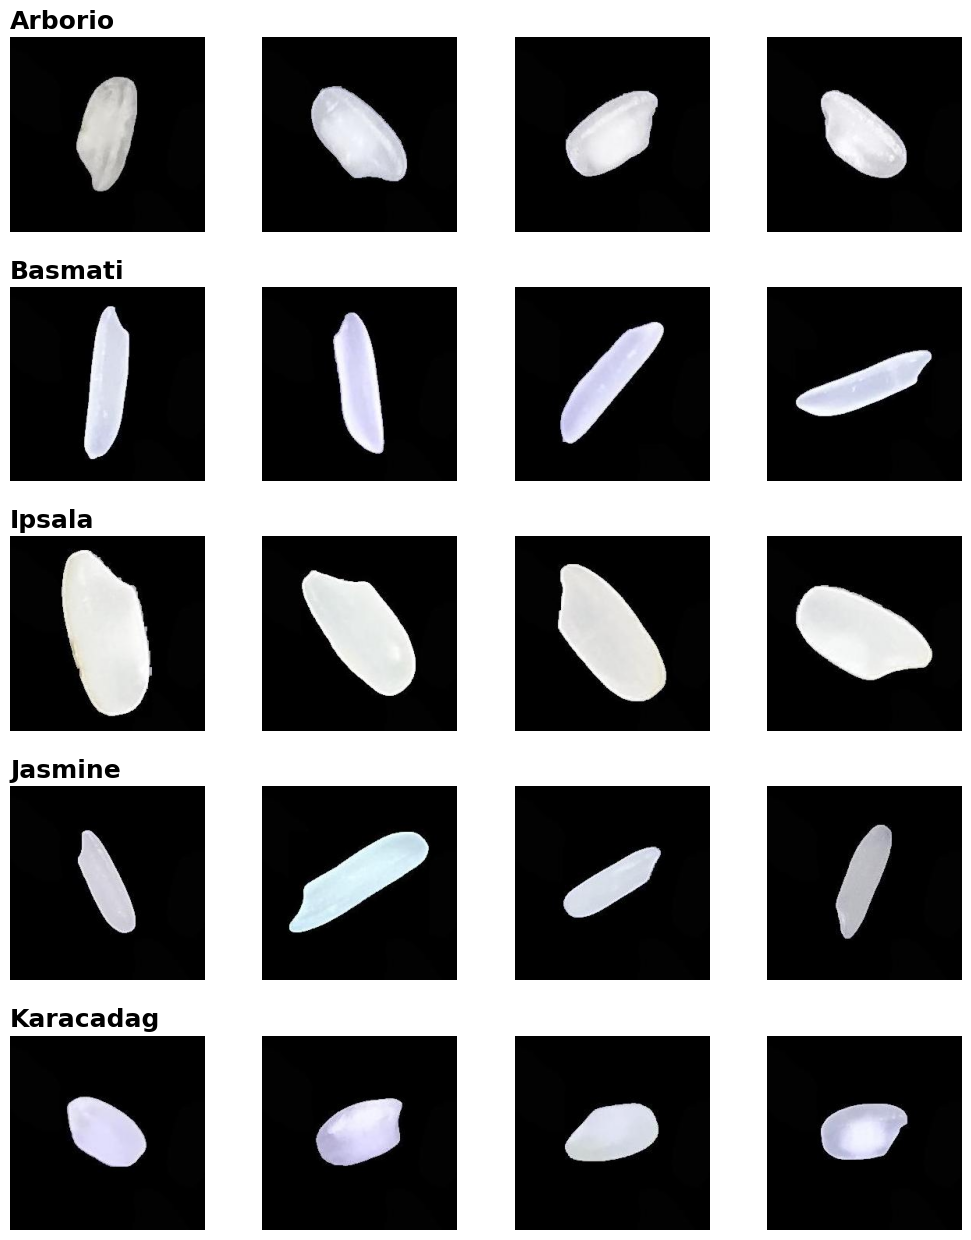

In [5]:
import matplotlib.pyplot as plt

n_examples = 4

fig, axes = plt.subplots(len(class_names), n_examples, figsize=(n_examples * 2.5, len(class_names) * 2.5))
for row, name in enumerate(class_names):
    paths = [f for f in train_ds.file_paths if os.path.basename(os.path.dirname(f)) == name][:n_examples]
    for col, path in enumerate(paths):
        ax = axes[row, col]
        ax.imshow(keras.utils.load_img(path))
        ax.axis("off")
        if col == 0:
            ax.set_title(name, loc="left", fontsize=18, fontweight="bold")
plt.tight_layout(w_pad=3, h_pad=2)
plt.show()


## 3. Model 1: one convolutional block

A minimal baseline CNN:

- **Input → Rescaling (1/255)**: maps pixel values from 0–255 to 0–1.
- **Conv2D** (32 filters, 3 × 3) → **BatchNormalization** → **ReLU**: learns local features such as edges and texture, with normalized activations for stable training.
- **MaxPooling2D** (2 × 2): halves the spatial resolution.
- **GlobalMaxPooling2D**: reduces each feature map to its strongest response, giving one value per filter.
- **Dense** (512, ReLU) → **Dropout** (0.25) → **Dense** (5, softmax): the classifier head. Dropout regularizes the fully connected layer.

The model has about 20,500 parameters. It is compiled with the Adam optimizer and sparse categorical cross-entropy, since the labels are integers.

In [6]:
model = Sequential()

model.add(Input(shape=(224, 224, 3)))
model.add(Rescaling(1./255)) 

model.add(Conv2D(filters=32,kernel_size=3, padding = "same" ))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=2,strides=2))


model.add(GlobalMaxPooling2D()) 

model.add(Dense(512))
model.add(Activation('relu'))
model.add(Dropout(0.25))

model.add(Dense(num_classes))
model.add(Activation('softmax'))

opt = keras.optimizers.Adam(learning_rate=.0001)

model.compile(loss='sparse_categorical_crossentropy', #point
              optimizer=opt,
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d            │ (None, 32)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         2,565 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 5)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,485 (80.02 KB)

 Trainable params: 20,421 (79.77 KB)

 Non-trainable params: 64 (256.00 B)

### 3.1 Training

Model 1 is trained for the full 20 epochs, without early stopping.

In [7]:
print ('Start training ...')
history = model.fit(
    train_ds,                    
    validation_data=test_ds,      
    epochs=epochs                
)

Start training ...
Epoch 1/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 32s 34ms/step - accuracy: 0.2960 - loss: 1.5892 - val_accuracy: 0.7504 - val_loss: 0.8935
Epoch 2/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 33s 35ms/step - accuracy: 0.7841 - loss: 0.7183 - val_accuracy: 0.8818 - val_loss: 0.4577
Epoch 3/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 30s 32ms/step - accuracy: 0.8663 - loss: 0.4474 - val_accuracy: 0.8965 - val_loss: 0.3357
Epoch 4/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 30s 32ms/step - accuracy: 0.9020 - loss: 0.3306 - val_accuracy: 0.9376 - val_loss: 0.2475
Epoch 5/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 30s 32ms/step - accuracy: 0.9202 - loss: 0.2666 - val_accuracy: 0.9478 - val_loss: 0.2058
Epoch 6/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 33s 35ms/step - accuracy: 0.9311 - loss: 0.2250 - val_accuracy: 0.9528 - val_loss: 0.1753
Epoch 7/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 35s 38ms/step - accuracy: 0.9381 - loss: 0.1966 - val_accuracy: 0.9570 - val_loss: 0.1549
Epoch 8/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 38s 41ms/step - accuracy: 0.946

### 3.2 Learning curve

Training and validation loss per epoch. The dashed line marks the epoch with the lowest validation loss.

Both losses decrease smoothly and stay close together, so the model doesn't overfit. The lowest validation loss is reached at the last epoch, which means the model was still improving when training ended.

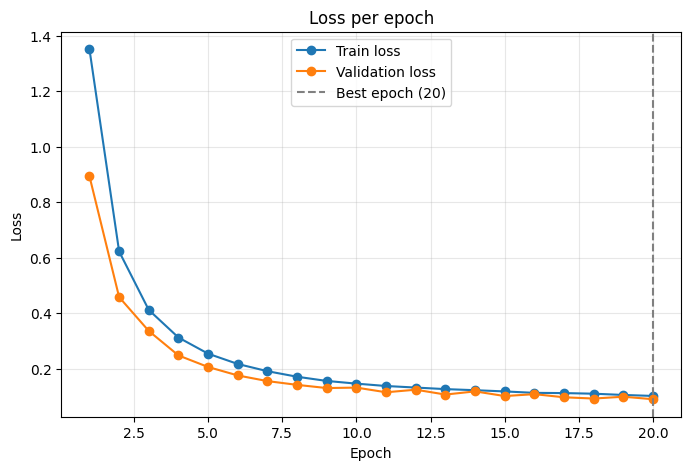

In [8]:
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(loss) + 1)
best_epoch = val_loss.index(min(val_loss)) + 1

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, loss, marker="o", label="Train loss")
plt.plot(epochs_range, val_loss, marker="o", label="Validation loss")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss per epoch")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 4. Model 2: two convolutional blocks

Model 2 adds a second Conv2D → BatchNormalization → ReLU → MaxPooling block. The second convolution works on the first one's feature maps, so it can combine simple features into larger patterns, such as the curvature of the grain's outline or the shape of its tip. This adds about 9,400 parameters, for a total of about 29,900. The classifier head is the same as in Model 1.

In [9]:
model = Sequential()

model.add(Input(shape=(224, 224, 3)))
model.add(Rescaling(1./255)) 

model.add(Conv2D(filters=32,kernel_size=3, padding = "same" ))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=2,strides=2))


model.add(Conv2D(filters=32,kernel_size=3, padding = "same"))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=2,strides=2))


model.add(GlobalMaxPooling2D()) 

model.add(Dense(512))
model.add(Activation('relu'))
model.add(Dropout(0.25))

model.add(Dense(num_classes))
model.add(Activation('softmax'))

opt = keras.optimizers.Adam(learning_rate=.0001)

model.compile(loss='sparse_categorical_crossentropy', #point
              optimizer=opt,
              metrics=['accuracy'])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d_1          │ (None, 32)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         2,565 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 5)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,861 (116.64 KB)

 Trainable params: 29,733 (116.14 KB)

 Non-trainable params: 128 (512.00 B)

### 4.1 Early stopping

Training stops when the validation loss hasn't improved by at least 0.001 for 4 consecutive epochs. The weights from the best epoch are then restored, so the final model is the best checkpoint rather than the last one.

In [10]:
from keras.callbacks import EarlyStopping


early_stop = EarlyStopping(
    monitor='val_loss',         
    patience=4, 
    min_delta=0.001,                
    restore_best_weights=True   
)

### 4.2 Training

In [11]:
print ('Start training ...')
history = model.fit(
    train_ds,                    
    validation_data=test_ds,      
    epochs=epochs,
    callbacks= [early_stop]              
)

Start training ...
Epoch 1/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 61s 64ms/step - accuracy: 0.4715 - loss: 1.2737 - val_accuracy: 0.8777 - val_loss: 0.3805
Epoch 2/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 59s 63ms/step - accuracy: 0.9026 - loss: 0.3065 - val_accuracy: 0.9515 - val_loss: 0.1623
Epoch 3/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 60s 64ms/step - accuracy: 0.9465 - loss: 0.1700 - val_accuracy: 0.9675 - val_loss: 0.1000
Epoch 4/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 61s 65ms/step - accuracy: 0.9660 - loss: 0.1077 - val_accuracy: 0.9763 - val_loss: 0.0736
Epoch 5/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 62s 66ms/step - accuracy: 0.9748 - loss: 0.0800 - val_accuracy: 0.9791 - val_loss: 0.0622
Epoch 6/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 62s 66ms/step - accuracy: 0.9790 - loss: 0.0658 - val_accuracy: 0.9766 - val_loss: 0.0771
Epoch 7/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 62s 66ms/step - accuracy: 0.9816 - loss: 0.0569 - val_accuracy: 0.9789 - val_loss: 0.0582
Epoch 8/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 63s 67ms/step - accuracy: 0.984

### 4.3 Learning curve

The loss falls much faster than in Model 1: validation accuracy passes 95% after only two epochs. The validation loss reaches its minimum at epoch 15, then fluctuates without improving, and early stopping ends training at epoch 19.

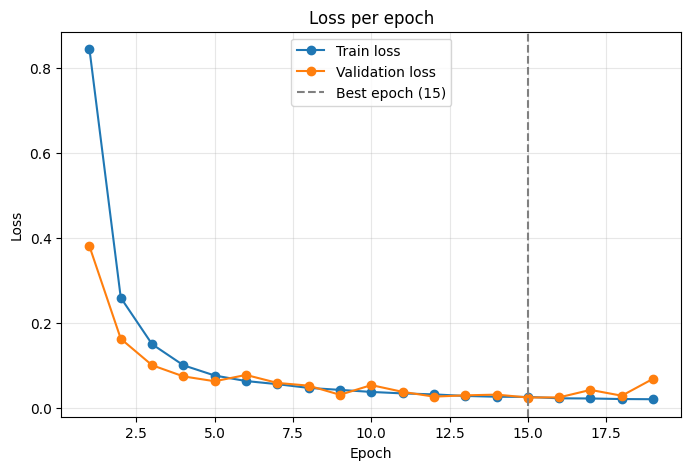

In [12]:
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(loss) + 1)
best_epoch = val_loss.index(min(val_loss)) + 1

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, loss, marker="o", label="Train loss")
plt.plot(epochs_range, val_loss, marker="o", label="Validation loss")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss per epoch")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. Model 3: input shape matched to the data

Models 1 and 2 declare an input shape of 224 × 224, while the pipeline produces 64 × 64 images. Model 3 has the same architecture as Model 2, but its input shape is set to **64 × 64 × 3** to match the data. Global max pooling makes the parameter count independent of the input size, so this experiment tests whether the declared input shape has any effect on the results.

In [13]:
model = Sequential()

model.add(Input(shape=(64, 64, 3)))
model.add(Rescaling(1./255)) 

model.add(Conv2D(filters=32,kernel_size=3, padding = "same"))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=2,strides=2))


model.add(Conv2D(filters=32,kernel_size=3, padding = "same"))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=2,strides=2))


model.add(GlobalMaxPooling2D()) 

model.add(Dense(512))
model.add(Activation('relu'))
model.add(Dropout(0.25))

model.add(Dense(num_classes))
model.add(Activation('softmax'))

opt = keras.optimizers.Adam(learning_rate=.0001)

model.compile(loss='sparse_categorical_crossentropy', #point
              optimizer=opt,
              metrics=['accuracy'])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d_2          │ (None, 32)             │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │         2,565 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 5)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,861 (116.64 KB)

 Trainable params: 29,733 (116.14 KB)

 Non-trainable params: 128 (512.00 B)

In [14]:
from keras.callbacks import EarlyStopping


early_stop = EarlyStopping(
    monitor='val_loss',         
    patience=4, 
    min_delta=0.001,                
    restore_best_weights=True   
)

### 5.1 Training

Model 3 uses the same early-stopping settings as Model 2.

In [15]:
print ('Start training ...')
history = model.fit(
    train_ds,                    
    validation_data=test_ds,      
    epochs=epochs,
    callbacks= [early_stop]              
)

Start training ...
Epoch 1/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 75s 79ms/step - accuracy: 0.3896 - loss: 1.4678 - val_accuracy: 0.9139 - val_loss: 0.3660
Epoch 2/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 69s 74ms/step - accuracy: 0.9010 - loss: 0.3197 - val_accuracy: 0.9507 - val_loss: 0.1623
Epoch 3/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 72s 76ms/step - accuracy: 0.9511 - loss: 0.1584 - val_accuracy: 0.9723 - val_loss: 0.1048
Epoch 4/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 67s 72ms/step - accuracy: 0.9675 - loss: 0.1074 - val_accuracy: 0.9772 - val_loss: 0.0834
Epoch 5/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 64s 68ms/step - accuracy: 0.9750 - loss: 0.0802 - val_accuracy: 0.9851 - val_loss: 0.0581
Epoch 6/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 64s 69ms/step - accuracy: 0.9789 - loss: 0.0660 - val_accuracy: 0.9745 - val_loss: 0.0702
Epoch 7/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 70s 74ms/step - accuracy: 0.9838 - loss: 0.0523 - val_accuracy: 0.9781 - val_loss: 0.0607
Epoch 8/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 64s 68ms/step - accuracy: 0.984

### 5.2 Learning curve

The curve closely follows Model 2's. The validation loss reaches its minimum at epoch 10, dips temporarily at epochs 11–13, and early stopping ends training at epoch 14.

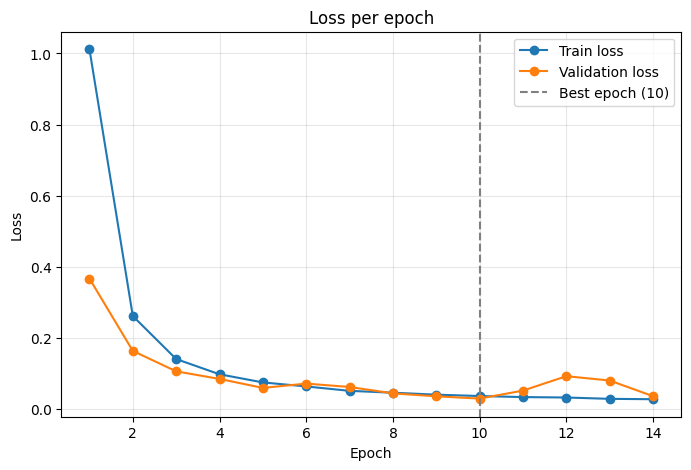

In [16]:
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(loss) + 1)
best_epoch = val_loss.index(min(val_loss)) + 1

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, loss, marker="o", label="Train loss")
plt.plot(epochs_range, val_loss, marker="o", label="Validation loss")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss per epoch")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 6. Conclusion

### Results

"Best epoch" is the epoch with the lowest validation loss. For Models 2 and 3 this is the checkpoint restored by early stopping. All accuracies are measured on the 15,000 held-out validation images.

| Model | Conv blocks | Input shape | Parameters | Epochs run | Best epoch | Val accuracy | Val loss | Time / epoch |
|---|---|---|---|---|---|---|---|---|
| Model 1 | 1 | 224 × 224 | 20,485 | 20 | 20 | 97.14% | 0.090 | ~36 s |
| Model 2 | 2 | 224 × 224 | 29,861 | 19 (early stopped) | 15 | 99.08% | **0.024** | ~64 s |
| Model 3 | 2 | 64 × 64 | 29,861 | 14 (early stopped) | 10 | **99.15%** | 0.028 | ~68 s |

### Analysis

- **The second convolutional block is the key improvement.** Going from one block to two raises validation accuracy from 97.1% to 99.1% and lowers the validation loss from 0.090 to 0.024. The error rate falls from 2.9% to about 0.9%, so roughly **three times fewer grains are misclassified**, for only about 9,400 extra parameters.
- **Why depth helps here.** Global max pooling keeps only the strongest response of each filter, so the classifier only knows *which* patterns appear in the image, not where. In Model 1 each feature sees a patch of about 4 × 4 pixels, which is enough for edges and texture but not for shape. In Models 2 and 3, the second convolution after pooling enlarges this to about 10 × 10 pixels, enough to capture the curvature and tips of the grain. Since the varieties differ mainly in shape, this matters.
- **Model 1 is limited by capacity, not overfitting.** Its training and validation curves stay close, and its best epoch is the last one, so it would gain a little more from longer training. However, it improves by less than 0.1 percentage points per epoch near the end, far below the level of the two-block models.
- **The declared input shape has no effect.** Models 2 and 3 are identical apart from the declared input shape. They reach the same accuracy (99.08% vs 99.15%, a difference of about 10 images out of 15,000) and take similar time per epoch, because both actually receive 64 × 64 images, and global max pooling makes the weights independent of image size. Model 3 reaching its best checkpoint earlier (epoch 10 vs 15) comes from random initialization and data order, not from the input shape. Declaring the true input shape is still good practice, because it makes the model summary show the real feature-map sizes.
- **No overfitting.** At their best epochs, training and validation accuracy differ by less than 0.5 percentage points for all three models. Training accuracy is sometimes slightly *below* validation accuracy, because dropout is active only during training.
- **Early stopping is valuable for the two-block models.** Their validation accuracy occasionally dips between epochs (for example, Model 2 fell to 97.6% at its last epoch and Model 3 to 96.8% at epoch 12). Restoring the best weights keeps the 99%+ checkpoint instead of the last one, and it also saved 1 and 6 epochs of training for Models 2 and 3.
- **Cost.** The second block roughly doubles training time per epoch (~36 s to ~64–68 s), because it adds a full convolution over 32 feature maps.

Overall, a compact CNN with fewer than 30,000 parameters classifies the five rice varieties with **over 99% accuracy** from 64 × 64 images. Depth was the decisive factor. The declared input shape made no difference to the results.